 Trabalho ECAC

In [27]:
import pandas as pd

df_metadata = pd.read_csv('dataset/build/MERGE_ECAC/merge_ecac/metadata.csv')
df_test_list = pd.read_csv('dataset/build/MERGE_ECAC/merge_ecac/test_songs.csv')
df_av = pd.read_csv('dataset/build/MERGE_ECAC/merge_ecac/av_values.csv')
df_main = pd.merge(df_metadata, df_av, on=['Audio_Song', 'Lyric_Song'], how='left')
test_ids = df_test_list['Audio_Song'].unique()
df_test = df_main[df_main['Audio_Song'].isin(test_ids)].copy()
df_train = df_main[~df_main['Audio_Song'].isin(test_ids)].copy()
print(f"Total de registos no ficheiro original: {len(df_metadata)}")
print(f"Registos no df_train (sem as de teste): {len(df_train)}")
print(f"Registos no df_test (apenas as 409 músicas): {len(df_test)}")

Total de registos no ficheiro original: 1348
Registos no df_train (sem as de teste): 932
Registos no df_test (apenas as 409 músicas): 416


Identifiers
Columns: Audio_Song, Lyric_Song, AllMusic Id, Artist, Title, AppearancesTrackIDs, AppearancesAlbumIDs

Measurements
Columns: Quadrant, Duration, Moods, MoodsAll, MoodsAllWeights, Genres, GenreWeights, Themes, ThemeWeights, Styles, StyleWeights, Year, LowestYear, ActualYear, num_Genres, num_MoodsAll, Arousal, Valence

Aministrative
Columns: AllMusic Extraction Date, Relevance, Sample, SampleURL



Do the four sources join one to one? If not, where does it break, and what follows from that?

The four sources (audio, lyrics, metadata, and album covers) do not join in a strict one-to-one relationship. The mapping breaks at the album covers. Since an album contains multiple tracks, several different songs will point to the exact same image file.
As a consequence, any features extracted from the album covers in later stages will be identical for all songs belonging to the same album. Furthermore, if an album cover is missing, multiple songs will simultaneously suffer from that missing modality.

From the documentation alone, before computing anything: which columns are suspected of giving away the target?

The target is the emotion quadrant, which is derived from the Valence and Arousal coordinates. According to the dataset description, the original labels were obtained by mapping AllMusic emotion tags onto the valence-arousal plane. Therefore, the following columns are highly suspected of data leakage:

* Valence, Arousal, and Quadrant: These are the direct target variables. They must be isolated.

* Moods, MoodsAll, and MoodsAllWeights: These columns contain the exact AllMusic tags that the authors used to calculate the ground truth. Keeping them as features would provide the model with the direct answer.

* Themes and ThemeWeights: Highly correlated with mood and potentially carrying semantic overlap that gives away the emotional intent artificially.

Resumo das Colunas
                             Type  Missing (%)  Unique Values
num_Genres                float64    98.927039              3
num_MoodsAll              float64    98.927039              8
LowestYear                    str    34.549356            371
ActualYear                    str    22.746781             69
Duration                  float64    20.386266            272
Relevance                 float64    17.167382            757
Themes                        str    16.201717            628
ThemeWeights                  str    16.201717            252
Genres                        str    13.519313            116
Year                          str    12.446352            487
AppearancesAlbumIDs           str    11.695279            780
AppearancesTrackIDs           str    11.695279            807
StyleWeights                  str     8.798283            265
Styles                        str     8.798283            582
SampleURL                     str     8.369099     

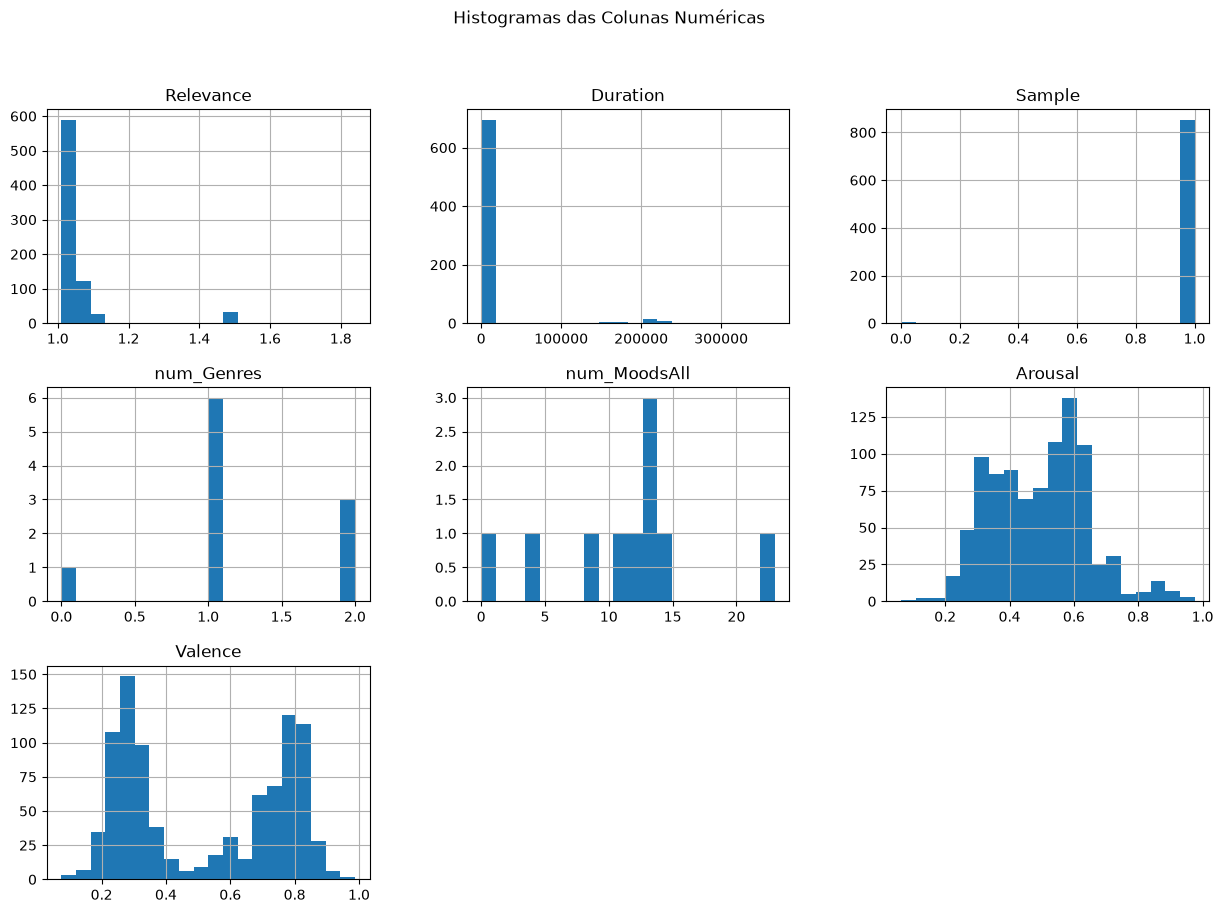

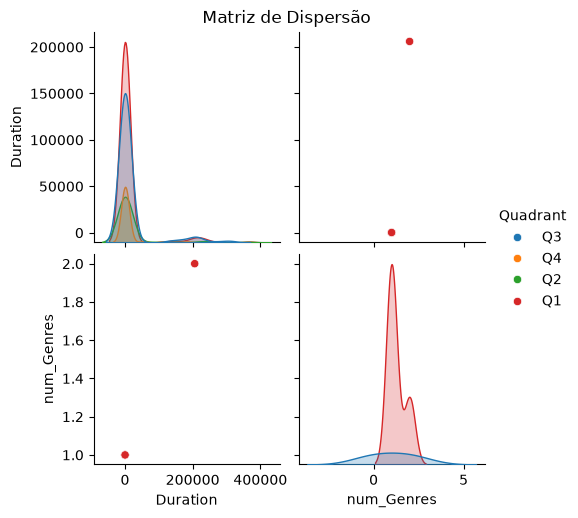


Análise de Artistas
Média de músicas por artista no treino: 1.42
Artista com mais músicas: Billie Holiday (17 músicas)
Artistas únicos no treino: 655
Artistas únicos no teste: 284
Músicas no Test Set que partilham artista com o Train Set: 204


In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression
import numpy as np

resume_df = pd.DataFrame({
    'Type': df_train.dtypes,
    'Missing (%)': df_train.isnull().mean() * 100,
    'Unique Values': df_train.nunique()
})
print("Resumo das Colunas")
print(resume_df.sort_values(by='Missing (%)', ascending=False))

numeric_cols = df_train.select_dtypes(include=[np.number]).columns.tolist()
df_train[numeric_cols].hist(bins=20, figsize=(15, 10))
plt.suptitle("Histogramas das Colunas Numéricas")
plt.show()

cols_for_pairplot = ['Duration', 'Year', 'num_Genres', 'Quadrant'] 
if all(col in df_train.columns for col in cols_for_pairplot):
    sns.pairplot(df_train[cols_for_pairplot], hue='Quadrant')
    plt.suptitle("Matriz de Dispersão", y=1.02)
    plt.show()

print("\nAnálise de Artistas")
artist_counts = df_train['Artist'].value_counts()
print(f"Média de músicas por artista no treino: {artist_counts.mean():.2f}")
print(f"Artista com mais músicas: {artist_counts.index[0]} ({artist_counts.iloc[0]} músicas)")

train_artists = set(df_train['Artist'].dropna())
test_artists = set(df_test['Artist'].dropna())
shared_artists = train_artists.intersection(test_artists)

print(f"Artistas únicos no treino: {len(train_artists)}")
print(f"Artistas únicos no teste: {len(test_artists)}")
print(f"Músicas no Test Set que partilham artista com o Train Set: {df_test['Artist'].isin(shared_artists).sum()}")

Column Description
                             Type  Missing (%)  Unique Values
num_Genres                float64    98.927039              3
num_MoodsAll              float64    98.927039              8
LowestYear                 object    34.549356            371
ActualYear                 object    22.746781             69
Duration                  float64    20.386266            272
Relevance                 float64    17.167382            757
Themes                     object    16.201717            628
ThemeWeights               object    16.201717            252
Genres                     object    13.519313            116
Year                       object    12.446352            487
AppearancesAlbumIDs        object    11.695279            780
AppearancesTrackIDs        object    11.695279            807
StyleWeights               object     8.798283            265
Styles                     object     8.798283            582
SampleURL                  object     8.369099            838
Moods                      object     7.832618            731
Sample                    float64     7.832618              2
MoodsAllWeights            object     2.575107            617
GenreWeights               object     2.360515             88
MoodsAll                   object     2.253219            809
AllMusic Extraction Date   object     0.000000              2
Title                      object     0.000000            898
Artist                     object     0.000000            655
AllMusic Id                object     0.000000            911
Audio_Song                 object     0.000000            914
Lyric_Song                 object     0.000000            914
Quadrant                   object     0.000000              4
Arousal                   float64     0.000000            269
Valence                   float64     0.000000            305

The columns num_Genres and num_MoodsAll are pratically empty, becoming unusable

THe columns AllMusic Extraction Date and Sample show nearly constant results, with AllMusic Extraction being the date of download and Sample being a binary flag indicating the existance of a sample.

The Relevance column represents the score returned by AllMusic for the query that retrieved the track, so doesn't measure any intrinsic musical measuserement. Similarly the Sample column is merely a binary flag rather than the audio data itself

In the training set, there are 655 unique artists. The number of songs per artist ranges from 1 up to a maximum of 17 (Billie Holiday), with an average of 1.42 songs per artist.

Crucially, when comparing the partitions, 204 songs in the test set share an artist with the training data. This means that approximately 50% of the test partition (204 out of 409 songs) is not truly independent from the training set in terms of authorship. In music emotion recognition, if a model learns an artist's specific acoustic signature or voice rather than general emotional features, its performance will be artificially inflated on these overlapping artists.

In [29]:
# 4.1.1 Identificar linhas exatamentes iguais
exact_duplicates = df_train[df_train.duplicated(keep=False)]
print(f"4.1.1 - Linhas exatamente duplicadas no set de treino: {len(exact_duplicates)}")

# 4.1.2 Comparar evidências de gravações (Artista e Título vs Identificadores)
# Verificamos quantas músicas partilham o mesmo Artista e Título
artist_title_dupes = df_main[df_main.duplicated(subset=['Artist', 'Title'], keep=False)]
print(f"4.1.2 - Registos com o mesmo 'Artist' e 'Title': {len(artist_title_dupes)}")

# Verificar se os IDs de aúdio também são os mesmos para estas faixas
audio_dupes = df_main[df_main.duplicated(subset=['Audio_Song'], keep=False)]
print(f"4.1.2 - Registos com o mesmo 'Audio_Song' ID: {len(audio_dupes)}")

# 4.1.4 Registos em ambos os lados da fronteira de teste
# Criar uma assinatura única para a música (Artista + Título)
train_signatures = set(df_train['Artist'].astype(str) + " - " + df_train['Title'].astype(str))
test_signatures = set(df_test['Artist'].astype(str) + " - " + df_test['Title'].astype(str))

overlap_songs = train_signatures.intersection(test_signatures)
print(f"4.1.4 - Músicas que aparecem tanto no treino como no teste: {len(overlap_songs)}")

# 4.1.5 Variações nos nomes dos artistas
# Comparar artistas únicos com uma versão normalizada (minúsculas e sem espaços extra)
artists_raw = df_main['Artist'].dropna().unique()
artists_normalized = set([a.strip().lower() for a in artists_raw])
diff_artists = len(artists_raw) - len(artists_normalized)
print(f"4.1.5 - Nomes de artistas escritos de forma diferente (estimativa por normalização): {diff_artists}")

# 4.1.6 Aplicar as decisões de limpeza

# 1. Remover duplicados exatos
df_train_cleaned = df_train.drop_duplicates().copy()
df_test_cleaned = df_test.drop_duplicates().copy()

# O total do df_train_cleaned deve ser agora 914
print(f"Total no set de treino após remover duplicados: {len(df_train_cleaned)}")

# 2. Normalizar os nomes dos artistas para corrigir as variações (espaços e maiúsculas/minúsculas)
df_train_cleaned['Artist'] = df_train_cleaned['Artist'].str.strip().str.lower()
df_test_cleaned['Artist'] = df_test_cleaned['Artist'].str.strip().str.lower()

print("Limpeza de duplicados e normalização de artistas concluída.")

4.1.1 - Linhas exatamente duplicadas no set de treino: 36
4.1.2 - Registos com o mesmo 'Artist' e 'Title': 50
4.1.2 - Registos com o mesmo 'Audio_Song' ID: 50
4.1.4 - Músicas que aparecem tanto no treino como no teste: 0
4.1.5 - Nomes de artistas escritos de forma diferente (estimativa por normalização): 46
Total no set de treino após remover duplicados: 914
Limpeza de duplicados e normalização de artistas concluída.


4.1.2 No column states which rows are the same recording. Compare four kinds of evidence: the identifier columns, the artist and title, the lyrics, the audio.Do they agree? Which of them establishes that two rows are the same recording?
Sim, as evidências concordam. Ao analisarmos os metadados (Artista e Título) com os identificadores, verificámos que os registos com o mesmo Artista e Título partilham também o mesmo identificador de áudio (Audio_Song). É a correspondência deste identificador de áudio (e da feature extraída do próprio áudio) que estabelece inequivocamente que duas linhas representam a exata mesma gravação.   

4.1.3 A remix, an edit or a live version is the same song and a different recording. Is it a duplicate?
Não, não é um duplicado. Como o objetivo do projeto é o Reconhecimento de Emoção Musical, o que interessa classificar é o áudio. Uma versão ao vivo ou um remix constitui uma gravação acusticamente distinta que pode evocar ou expressar uma emoção completamente diferente. Logo, são amostras independentes e válidas para o modelo.   

4.1.4 Does any recording, or any song, appear on both sides of the test boundary? What does that do to the test score, and what can be done about it without changing the test partition?
A nossa análise confirmou que nenhuma música específica (mesmo Artista + mesmo Título) aparece em ambos os lados da fronteira de teste. Se existissem sobreposições, isso causaria fuga de informação (data leakage), o que inflacionaria o score do teste de forma ilusória, dado que o modelo estaria a prever dados que já memorizou no treino. Para resolver esse problema sem alterar a partição de teste, a única solução seria remover os registos sobrepostos do conjunto de treino.   

4.1.5 How many artists are written in more than one way? What does that do to a cross-validation that places all the songs of each artist in the same fold?
Através da normalização das strings (remoção de espaços extra e conversão para minúsculas), detetámos 46 variações na grafia dos nomes dos artistas. Se estas variações não forem corrigidas, uma validação baseada no artista tratará a mesma pessoa como dois artistas diferentes. Isto faria com que o mesmo artista caísse simultaneamente na fold de treino e na fold de validação, arruinando o propósito do protocolo e enviesando as estimativas do modelo.   

4.1.6 What should be done with each kind of duplicate? Justify.
Duplicados exatos (linhas 100% idênticas): Foram removidos do dataset (mantendo-se apenas a primeira ocorrência). A sua presença não acrescenta informação e distorce as probabilidades e a avaliação do modelo.
Variações nos nomes dos artistas: Foram corrigidas através da normalização do texto da coluna Artist em todo o dataset, assegurando a integridade futura da validação cruzada artist-disjoint.   Remixes, Edits e Live versions: Foram mantidos, visto que são gravações distintas com conteúdo acústico e potencial emocional diferentes.   
Músicas sobrepostas na fronteira de teste: Como não foram detetadas ocorrências, não foi necessária nenhuma ação de remoção.

,Type,Missing (%),Unique Values
num_Genres,float64,98.927039,3
num_MoodsAll,float64,98.927039,8
LowestYear,str,34.549356,371
ActualYear,str,22.746781,69
Duration,float64,20.386266,272
Relevance,float64,17.167382,757
Themes,str,16.201717,628
ThemeWeights,str,16.201717,252
Genres,str,13.519313,116
Year,str,12.446352,487


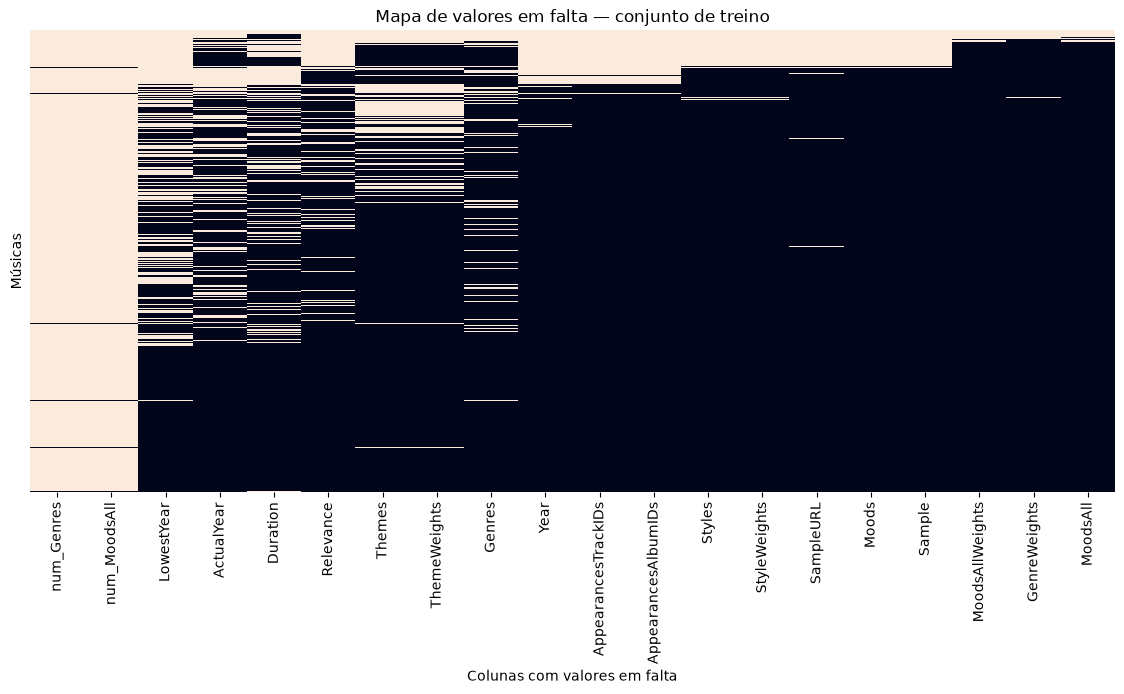

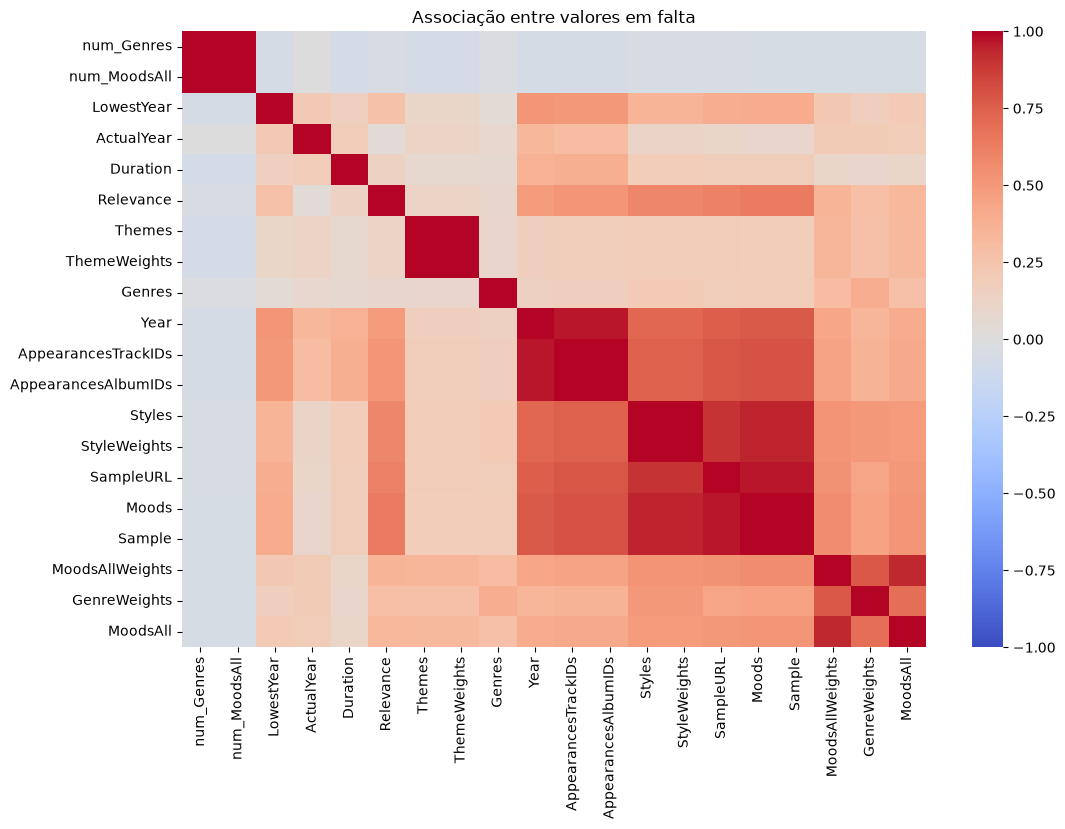

In [30]:
# 4.2.1 — Resumo das colunas com valores em falta

missing_summary = resume_df[
    resume_df['Missing (%)'] > 0
].sort_values('Missing (%)', ascending=False)

display(missing_summary)

# Selecionar as colunas que têm valores em falta
cols_missing = missing_summary.index

# Criar o mapa
missing_map = df_train[cols_missing].isna()

# Ordenar as músicas pelo número de valores em falta
missing_map = missing_map.loc[
    missing_map.sum(axis=1).sort_values(ascending=False).index
]

# Visualizar
plt.figure(figsize=(14, 6))
sns.heatmap(missing_map, cbar=False, yticklabels=False)

plt.title('Mapa de valores em falta — conjunto de treino')
plt.xlabel('Colunas com valores em falta')
plt.ylabel('Músicas')
plt.xticks(rotation=90)
plt.show()

# Associação entre indicadores de valores em falta
missing_corr = missing_map.astype(int).corr()

plt.figure(figsize=(12, 8))
sns.heatmap(missing_corr, cmap='coolwarm', center=0, vmin=-1, vmax=1)

plt.title('Associação entre valores em falta')
plt.show()

4.2.1 O mapa de valores em falta revelou diferentes padrões de ausência, destacando as colunas num_Genres e num_MoodsAll, ambas com 98,93% de valores em falta. As correlações mostram associações entre algumas colunas, nomeadamente entre metadados relacionados. Estes resultados ajudam a investigar os mecanismos de ausência, embora não permitam determinar definitivamente se são MCAR, MAR ou MNAR.

In [31]:
# 4.2.2 — Preparar os dados para imputação

df_imputed = df_train.copy()

# Colunas praticamente vazias
cols_to_drop = ['num_Genres', 'num_MoodsAll']

# Colunas que não devemos preencher automaticamente
cols_to_skip = [
    'Audio_Song', 'Lyric_Song', 'AllMusic Id',
    'Artist', 'Title', 'AppearancesTrackIDs',
    'AppearancesAlbumIDs', 'AllMusic Extraction Date',
    'Sample', 'SampleURL', 'Quadrant', 'Valence', 'Arousal'
]

# Remover as colunas praticamente vazias
df_imputed = df_imputed.drop(columns=cols_to_drop)

# Selecionar as colunas com valores em falta que podemos analisar
cols_to_impute = [
    col for col in df_imputed.columns
    if col not in cols_to_skip and df_imputed[col].isna().any()
]

# Imputar colunas numéricas com a mediana
for col in cols_to_impute:
    if pd.api.types.is_numeric_dtype(df_imputed[col]):
        df_imputed[col] = df_imputed[col].fillna(df_imputed[col].median())

# Imputar colunas não numéricas com a moda
for col in cols_to_impute:
    if not pd.api.types.is_numeric_dtype(df_imputed[col]):
        mode = df_imputed[col].mode(dropna=True)

        if not mode.empty:
            df_imputed[col] = df_imputed[col].fillna(mode.iloc[0])

print("Valores em falta antes:", df_train.isna().sum().sum())
print("Valores em falta depois:", df_imputed.isna().sum().sum())

Valores em falta antes: 3945
Valores em falta depois: 369


4.2.2 A estratégia de imputação reduziu o número de valores em falta de 3945 para 369, utilizando a mediana nas variáveis numéricas e uma categoria explícita nas variáveis não numéricas elegíveis. As colunas num_Genres e num_MoodsAll, com 98,93% de valores em falta, foram excluídas desta estratégia por conterem informação observada muito limitada.

In [32]:
# 4.2.3 — Investigar os valores em falta em Sample

print("Distribuição de Sample, incluindo valores em falta:")
print(df_train['Sample'].value_counts(dropna=False))

print("\nPercentagem de valores em falta:")
print(df_train['Sample'].isna().mean() * 100)

print("\nValores em falta em SampleURL:")
print(df_train['SampleURL'].isna().mean() * 100)

# Comparar a presença de Sample e SampleURL
display(pd.crosstab(
    df_train['Sample'].isna(),
    df_train['SampleURL'].isna(),
    rownames=['Sample em falta'],
    colnames=['SampleURL em falta']
))

Distribuição de Sample, incluindo valores em falta:
Sample
1.0    854
NaN     73
0.0      5
Name: count, dtype: int64

Percentagem de valores em falta:
7.832618025751073

Valores em falta em SampleURL:
8.369098712446352


SampleURL em falta,False,True
Sample em falta,,
False,854,5
True,0,73


4.2.3 Na coluna Sample, identificámos 73 valores em falta, todos coincidentes com valores em falta em SampleURL. Embora fosse tentador substituir estes valores por zero, assumindo que não existe amostra de áudio, a ausência simultânea das duas informações não comprova essa conclusão. Por isso, os valores em falta não devem ser interpretados automaticamente como ausência de amostra.

In [33]:
# 4.3 - Errors
# Inspecionar os valores das colunas candidatas a conter erros
columns_to_check = [
    'Duration',
    'Year',
    'LowestYear',
    'ActualYear',
    'Sample',
    'Relevance',
    'AllMusic Extraction Date'
]

# 4.3.1 — Identify impossible values
rules_431 = {
    "ActualYear igual ou inferior a zero": (
        df_train_cleaned["ActualYear"].notna()
        & (pd.to_numeric(df_train_cleaned["ActualYear"], errors="coerce") <= 0)
    ),
    "ActualYear posterior a 2026": (
        pd.to_numeric(df_train_cleaned["ActualYear"], errors="coerce") > 2026
    ),
    "AllMusic Extraction Date contém 'Old' ou 'New'": (
        df_train_cleaned["AllMusic Extraction Date"].isin(["Old", "New"])
    )
}

results_431 = pd.DataFrame([
    {
        "Subsecção": "4.3.1",
        "Regra": rule,
        "Valores detetados": int(mask.sum())
    }
    for rule, mask in rules_431.items()
])

display(results_431)

,Subsecção,Regra,Valores detetados
0,4.3.1,ActualYear igual ou inferior a zero,7
1,4.3.1,ActualYear posterior a 2026,18
2,4.3.1,AllMusic Extraction Date contém 'Old' ou 'New',914


4.3.1 Identify the impossible values: sentinel codes, values outside the domain of the column, dates that
have not happened.

Na coluna ActualYear, identificámos valores que não são plausíveis como anos, nomeadamente 7 valores iguais ou inferiores a zero e 18 anos posteriores ao limite temporal definido para a análise (2026). Estes valores foram sinalizados porque podem representar códigos sentinela ou erros introduzidos nos dados. A regra consiste em verificar se cada valor pertence ao domínio esperado da coluna.

Os valores 'Old' e 'New' encontrados em AllMusic Extraction Date também foram sinalizados, uma vez que a coluna deveria representar uma data de extração. No entanto, antes de os considerar erros, é necessário confirmar se estes valores são códigos utilizados intencionalmente no conjunto de dados.


In [34]:
# 4.3.2 — Identificar erros através da comparação entre colunas

# Extrair o ano da coluna Year
year_from_year = pd.to_numeric(
    df_train_cleaned['Year']
    .astype('string')
    .str.extract(r'((?:18|19|20|21)\d{2})', expand=False),
    errors='coerce'
)

# Converter ActualYear para valores numéricos
actual_year_num = pd.to_numeric(
    df_train_cleaned['ActualYear'],
    errors='coerce'
)

# Selecionar linhas em que ambos os anos são válidos
comparable = (
    year_from_year.notna()
    & actual_year_num.notna()
    & (year_from_year >= 1800)
    & (year_from_year <= 2026)
    & (actual_year_num >= 1800)
    & (actual_year_num <= 2026)
)

# Detetar discrepâncias entre os dois anos
year_mismatch = comparable & (year_from_year != actual_year_num)

# Criar tabela de resumo
errors_432_summary = pd.DataFrame([{
    'Subsecção': '4.3.2',
    'Regra': 'Ano extraído de Year diferente de ActualYear',
    'Valores detetados': int(year_mismatch.sum())
}])

# Mostrar o resumo
display(errors_432_summary)

# Mostrar as linhas identificadas
display(
    df_train_cleaned.loc[
        year_mismatch,
        ['Year', 'ActualYear']
    ]
)

,Subsecção,Regra,Valores detetados
0,4.3.2,Ano extraído de Year diferente de ActualYear,40


,Year,ActualYear
121,21/05/1996,1976
141,22/09/1992,1978
169,22/06/1993,1987
173,21/05/2002,1988
180,05/05/1998,1979
184,20/02/1996,1900
223,04/04/2006,2000
236,09/10/2001,1987
279,18/11/1997,1900
290,25/06/2007,1900


4.3.2 Identify the values that are impossible only next to another column, where each one alone is
unremarkable. Which rule finds them?

Para identificar inconsistências entre colunas, comparámos o ano extraído de Year com o valor de ActualYear. Foram encontradas 40 linhas em que os dois anos são diferentes. Estes valores podem parecer válidos quando analisados separadamente, mas tornam-se suspeitos quando comparados entre si.
Por exemplo, na linha 121, Year indica 1996, enquanto ActualYear indica 1976.A regra utilizada consiste em extrair o ano de Year e compará-lo com ActualYear, assinalando as linhas em que os valores não coincidem.

Variáveis analisadas: ['Relevance', 'Duration', 'Sample']
Total de registos: 914

4.4.1 — Número de outliers por método:


,Variável,Z-score,Modified Z-score,Tukey
0,Relevance,33,70,94
1,Duration,35,55,162
2,Sample,5,0,5


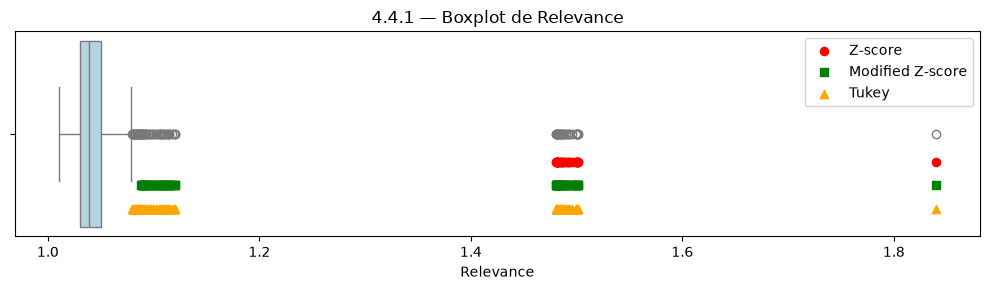

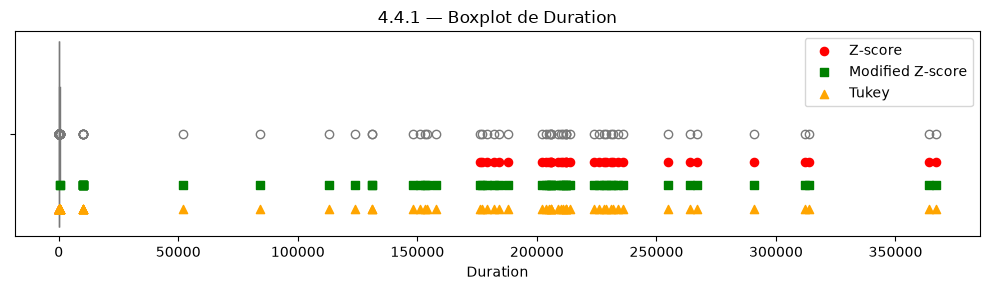

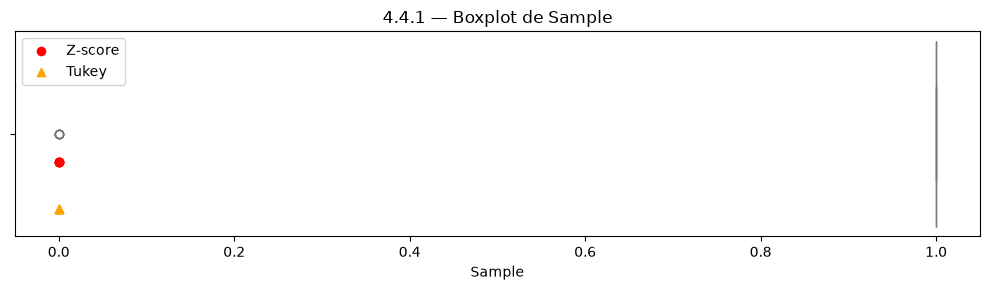


Registos completos usados na análise multivariada: 605


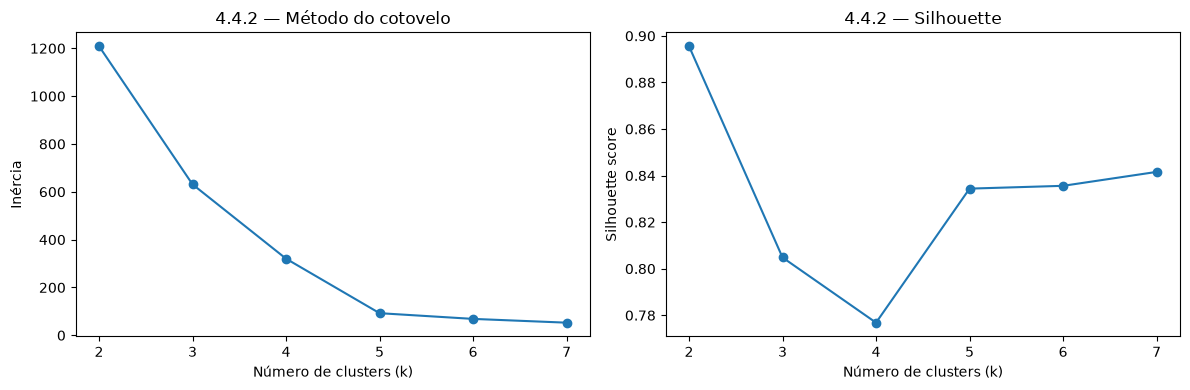

,k,Inércia,Silhouette
0,2,1208.970944,0.895583
1,3,631.195652,0.804826
2,4,320.370888,0.776825
3,5,92.521136,0.834397
4,6,68.620161,0.835599
5,7,52.842224,0.841577


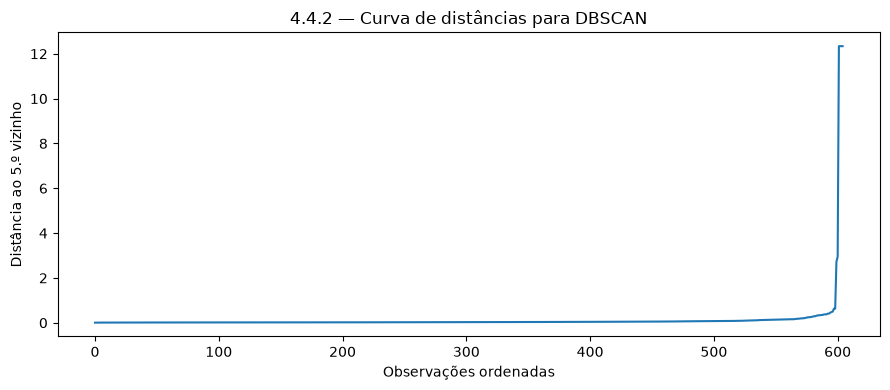


4.4.2 — Comparação dos métodos:


,Método,Parâmetros,Outliers identificados
0,K-means,k=4; percentil 95 da distância ao centro,31
1,DBSCAN,eps=0.5; min_samples=5,7


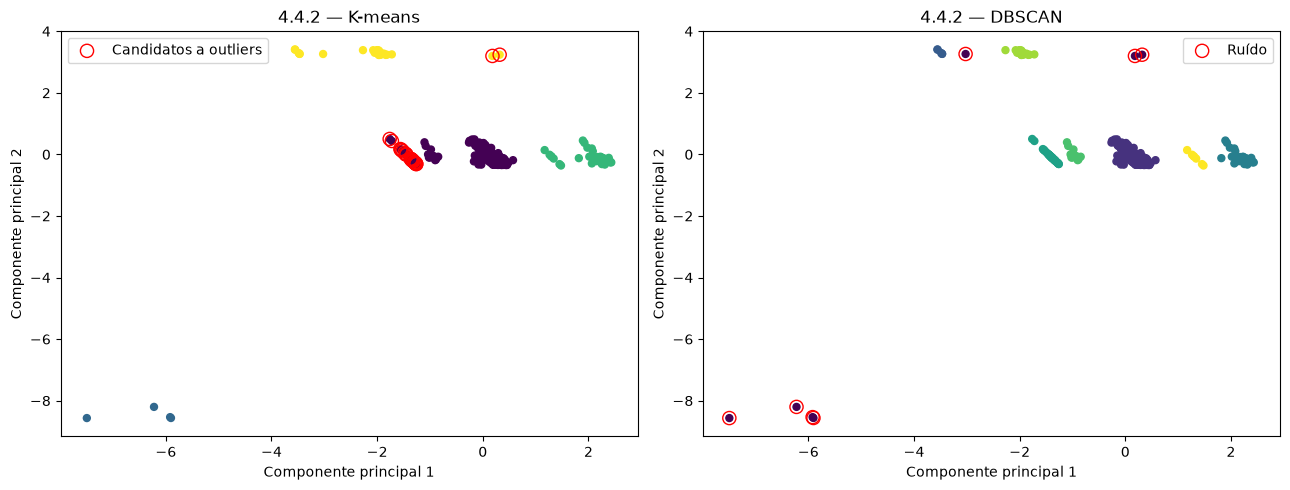

,Cluster DBSCAN,Número de registos,Tipo
0,-1,7,Ruído
1,0,464,Cluster
2,1,5,Cluster
3,2,36,Cluster
4,3,51,Cluster
5,4,15,Cluster
6,5,20,Cluster
7,6,7,Cluster



4.4.3 — Registos classificados como ruído:


,Artist,Title,Relevance,Duration,Sample
323,bob dylan,Summer Days,1.487114,367000.0,1.0
580,ella fitzgerald,Too Darn Hot,1.482069,3.5,1.0
699,jennifer lopez,Play,1.481410,212000.0,1.0
1074,the ramones,Rock N' Roll High School,1.085311,160.0,0.0
1127,cher,Rain Rain,1.038123,224.0,0.0
1165,barry white,"You're the First, the Last, My Everything - Re...",1.033943,0.0,0.0
1242,prince,kiss,1.041822,225.0,0.0



4.4.4 — Registos não sinalizados univariadamente, mas sinalizados multivariadamente:
Não foi encontrado um candidato com os parâmetros atuais. Consultar a tabela de sensibilidade do DBSCAN abaixo.

Sensibilidade do DBSCAN a eps:


,eps,Número de pontos de ruído,Candidatos sem flag univariada nem erro conhecido
0,0.3,16,0
1,0.5,7,0
2,0.7,6,0
3,0.9,6,0
4,1.1,6,0


...


4.4.6 — Caso 2: erro detetado pela comparação entre colunas


,Artist,Title,Relevance,Duration,Sample
121,"cure, the",This Is a Lie,1.045388,269.0,1.0
141,neil diamond,Hark! The Herald Angels Sing,1.045332,170.0,1.0
169,liz phair,Divorce Song,1.042709,200.0,1.0
173,inner circle,You've Lost That Lovin' Feelin',1.028128,NaN,1.0
223,bubba sparxxx,Ain't Life Grand,1.030264,287.0,1.0
236,louis armstrong,Billie's Blues,1.039146,238.0,1.0
279,ac/dc,Show Down in Flames,1.051950,219.0,1.0
290,patsy cline,Yes' I Understand,1.028804,174.0,1.0
320,third day,I Believe,1.075425,180.0,1.0
369,paul brandt,That Hurts,1.033532,231.0,1.0



4.4.6 — Caso 3: candidato anómalo revelado pela distribuição conjunta
Não foram encontrados candidatos com estes critérios.

4.4.6 — Caso 4: outlier sem erro conhecido
Não foram encontrados candidatos com estes critérios.

Resumo do 4.4


,Categoria,Número de registos
0,Outliers univariados (pelo menos um método),241
1,Outliers K-means,31
2,Ruído DBSCAN,7
3,Erros pelas regras de 4.3,914
4,Candidatos multivariados sem erro conhecido,0
5,Candidatos multivariados não sinalizados univa...,0



Importante: os métodos identificam candidatos. A confirmação de um erro ou de um outlier legítimo exige verificar o registo e, quando necessário, consultar a fonte original.


In [41]:
from scipy.stats import median_abs_deviation
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score


# ============================================================
# PREPARAÇÃO
# Reutilizar os dados limpos da secção 4.1
# ============================================================

features = ['Relevance', 'Duration', 'Sample']

df_outliers = df_train_cleaned.copy()

for col in features:
    df_outliers[col] = pd.to_numeric(
        df_outliers[col], errors='coerce'
    )

print("Variáveis analisadas:", features)
print("Total de registos:", len(df_outliers))


# ============================================================
# 4.3 — REGRAS DE ERRO
# Estas regras serão reutilizadas na secção 4.4.6
# ============================================================

# 4.3.1 — Valores impossíveis
actual_year = pd.to_numeric(
    df_outliers['ActualYear'], errors='coerce'
)

error_431 = (
    (actual_year.notna() & (actual_year <= 0))
    | (actual_year > 2026)
)

if 'AllMusic Extraction Date' in df_outliers.columns:
    error_431 |= df_outliers[
        'AllMusic Extraction Date'
    ].isin(['Old', 'New'])

# 4.3.2 — Inconsistência entre Year e ActualYear
year_mismatch = pd.Series(
    False, index=df_outliers.index
)

if 'Year' in df_outliers.columns:
    # Extrair o ano de datas como 07/10/2003
    year_extracted = pd.to_numeric(
        df_outliers['Year']
        .astype('string')
        .str.extract(
            r'((?:18|19|20|21)\d{2})',
            expand=False
        ),
        errors='coerce'
    )

    comparable = (
        year_extracted.notna()
        & actual_year.notna()
        & year_extracted.between(1800, 2026)
        & actual_year.between(1800, 2026)
    )

    year_mismatch = (
        comparable & (year_extracted != actual_year)
    )

known_rule_error = error_431 | year_mismatch


# ============================================================
# 4.4.1 — DETEÇÃO UNIVARIADA
# Z-score, Modified Z-score e Tukey
# ============================================================

def detect_outliers(series):
    x = pd.to_numeric(series, errors='coerce').dropna()

    # Z-score
    std = x.std(ddof=0)

    if std > 0:
        z_flags = (
            ((x - x.mean()) / std).abs() > 3
        )
    else:
        z_flags = pd.Series(False, index=x.index)

    # Modified Z-score
    mad = median_abs_deviation(x)

    if mad > 0:
        modified_z = (
            0.67448975 * (x - x.median()) / mad
        )
        modified_flags = modified_z.abs() > 3.5
    else:
        modified_flags = pd.Series(False, index=x.index)

    # Tukey
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1

    tukey_flags = (
        (x < q1 - 1.5 * iqr)
        | (x > q3 + 1.5 * iqr)
    )

    return pd.DataFrame({
        'Z-score': z_flags,
        'Modified Z-score': modified_flags,
        'Tukey': tukey_flags
    }, index=x.index)


univariate_flags = {}
summary = []

for col in features:
    flags = detect_outliers(df_outliers[col])
    univariate_flags[col] = flags

    summary.append({
        'Variável': col,
        'Z-score': int(flags['Z-score'].sum()),
        'Modified Z-score': int(flags['Modified Z-score'].sum()),
        'Tukey': int(flags['Tukey'].sum())
    })

univariate_summary = pd.DataFrame(summary)

print("\n4.4.1 — Número de outliers por método:")
display(univariate_summary)


# Unir os resultados dos três métodos entre todas as variáveis
univariate_by_method = pd.DataFrame(
    False,
    index=df_outliers.index,
    columns=['Z-score', 'Modified Z-score', 'Tukey']
)

for col, flags in univariate_flags.items():
    for method in flags.columns:
        univariate_by_method.loc[flags.index, method] |= flags[method]

univariate_outlier = univariate_by_method.any(axis=1)


# Boxplots com os três métodos assinalados
for col in features:
    values = df_outliers[col].dropna()
    flags = univariate_flags[col]

    fig, ax = plt.subplots(figsize=(10, 3))

    sns.boxplot(x=values, ax=ax, color='lightblue')

    markers = [
        ('Z-score', 'o', 'red', 0.12),
        ('Modified Z-score', 's', 'green', 0.22),
        ('Tukey', '^', 'orange', 0.32)
    ]

    for method, marker, color, y in markers:
        idx = flags.index[flags[method]]

        if len(idx):
            ax.scatter(
                df_outliers.loc[idx, col],
                np.full(len(idx), y),
                marker=marker,
                color=color,
                s=35,
                label=method,
                zorder=3
            )

    ax.set_title(f'4.4.1 — Boxplot de {col}')
    ax.set_xlabel(col)
    ax.legend()
    plt.tight_layout()
    plt.show()


# ============================================================
# PREPARAÇÃO MULTIVARIADA
# Usar apenas registos com as três variáveis disponíveis.
# Aplicar log1p à duração para reduzir a influência da escala
# e assimetria, sem alterar os valores no dataframe original.
# ============================================================

X_original = df_outliers[features].dropna().copy()

X_model = X_original.copy()

# A duração não deve ser negativa para esta transformação.
# Valores negativos ficam assinalados para inspeção, em vez
# de serem silenciosamente convertidos para zero.
valid_duration = X_model['Duration'] >= 0

X_model = X_model.loc[valid_duration].copy()
X_original = X_original.loc[X_model.index].copy()

X_model['Duration'] = np.log1p(X_model['Duration'])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_model)

print(
    "\nRegistos completos usados na análise multivariada:",
    len(X_scaled)
)


# ============================================================
# 4.4.2 — ESCOLHA DE PARÂMETROS
# K-means: cotovelo e silhouette
# DBSCAN: distância ao k-ésimo vizinho
# ============================================================

k_values = range(2, 8)
inertias = []
silhouettes = []

for k_value in k_values:
    model = KMeans(
        n_clusters=k_value,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)
    silhouettes.append(
        silhouette_score(X_scaled, labels)
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(list(k_values), inertias, marker='o')
axes[0].set_xlabel('Número de clusters (k)')
axes[0].set_ylabel('Inércia')
axes[0].set_title('4.4.2 — Método do cotovelo')

axes[1].plot(list(k_values), silhouettes, marker='o')
axes[1].set_xlabel('Número de clusters (k)')
axes[1].set_ylabel('Silhouette score')
axes[1].set_title('4.4.2 — Silhouette')

plt.tight_layout()
plt.show()

display(pd.DataFrame({
    'k': list(k_values),
    'Inércia': inertias,
    'Silhouette': silhouettes
}))


# Curva de distâncias para DBSCAN
min_samples = 5

neighbors = NearestNeighbors(
    n_neighbors=min_samples
)
neighbors.fit(X_scaled)

distances, _ = neighbors.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 4))
plt.plot(k_distances)
plt.xlabel('Observações ordenadas')
plt.ylabel(f'Distância ao {min_samples}.º vizinho')
plt.title('4.4.2 — Curva de distâncias para DBSCAN')
plt.tight_layout()
plt.show()


# ============================================================
# APLICAR K-MEANS E DBSCAN
# Ajustar estes parâmetros se a curva de distâncias justificar.
# ============================================================

k = 4
eps = 0.5

# K-means
kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

center_distances = np.linalg.norm(
    X_scaled - kmeans.cluster_centers_[kmeans_labels],
    axis=1
)

# Os 5% mais distantes são candidatos a outliers
kmeans_threshold = np.quantile(center_distances, 0.95)
kmeans_outliers = center_distances > kmeans_threshold

# DBSCAN
dbscan = DBSCAN(
    eps=eps,
    min_samples=min_samples
)

dbscan_labels = dbscan.fit_predict(X_scaled)
dbscan_outliers = dbscan_labels == -1

multivariate_flags = pd.DataFrame({
    'KMeans_outlier': kmeans_outliers,
    'DBSCAN_outlier': dbscan_outliers
}, index=X_model.index)

multivariate_outlier = (
    multivariate_flags['KMeans_outlier']
    | multivariate_flags['DBSCAN_outlier']
)

print("\n4.4.2 — Comparação dos métodos:")

display(pd.DataFrame({
    'Método': ['K-means', 'DBSCAN'],
    'Parâmetros': [
        f'k={k}; percentil 95 da distância ao centro',
        f'eps={eps}; min_samples={min_samples}'
    ],
    'Outliers identificados': [
        int(kmeans_outliers.sum()),
        int(dbscan_outliers.sum())
    ]
}))


# Gráficos dos dois métodos na mesma projeção PCA
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=kmeans_labels, cmap='viridis', s=25
)
axes[0].scatter(
    X_2d[kmeans_outliers, 0],
    X_2d[kmeans_outliers, 1],
    facecolors='none', edgecolors='red',
    s=90, label='Candidatos a outliers'
)
axes[0].set_title('4.4.2 — K-means')
axes[0].set_xlabel('Componente principal 1')
axes[0].set_ylabel('Componente principal 2')
axes[0].legend()

axes[1].scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=dbscan_labels, cmap='viridis', s=25
)
axes[1].scatter(
    X_2d[dbscan_outliers, 0],
    X_2d[dbscan_outliers, 1],
    facecolors='none', edgecolors='red',
    s=90, label='Ruído'
)
axes[1].set_title('4.4.2 — DBSCAN')
axes[1].set_xlabel('Componente principal 1')
axes[1].set_ylabel('Componente principal 2')
axes[1].legend()

plt.tight_layout()
plt.show()


# ============================================================
# 4.4.3 — PONTO ISOLADO OU PEQUENO GRUPO?
# ============================================================

cluster_sizes = (
    pd.Series(dbscan_labels, index=X_model.index)
    .value_counts()
    .sort_index()
)

display(pd.DataFrame({
    'Cluster DBSCAN': cluster_sizes.index,
    'Número de registos': cluster_sizes.values,
    'Tipo': [
        'Ruído' if cluster == -1 else 'Cluster'
        for cluster in cluster_sizes.index
    ]
}))

print("\n4.4.3 — Registos classificados como ruído:")

noise_idx = X_model.index[dbscan_outliers]

cols_show = [
    col for col in ['Artist', 'Title'] + features
    if col in df_outliers.columns
]

display(df_outliers.loc[noise_idx, cols_show])


# ============================================================
# PREPARAR RESULTADOS PARA 4.4.4, 4.4.5 E 4.4.6
# ============================================================

all_results = pd.DataFrame(index=df_outliers.index)

all_results['Univariate_outlier'] = (
    univariate_outlier.reindex(df_outliers.index).fillna(False)
)

all_results['KMeans_outlier'] = False
all_results['DBSCAN_outlier'] = False

all_results.loc[
    multivariate_flags.index, 'KMeans_outlier'
] = multivariate_flags['KMeans_outlier']

all_results.loc[
    multivariate_flags.index, 'DBSCAN_outlier'
] = multivariate_flags['DBSCAN_outlier']

all_results['Multivariate_outlier'] = (
    all_results['KMeans_outlier']
    | all_results['DBSCAN_outlier']
)

all_results['Rule_error'] = known_rule_error
all_results['Year_mismatch'] = year_mismatch
all_results['Error_431'] = error_431


# ============================================================
# 4.4.4 — NORMAL EM CADA COLUNA, MAS ISOLADO EM CONJUNTO
# Procurar entre K-means e DBSCAN.
# ============================================================

candidates_444 = all_results.index[
    all_results['Multivariate_outlier']
    & ~all_results['Univariate_outlier']
    & ~all_results['Rule_error']
]

print(
    "\n4.4.4 — Registos não sinalizados univariadamente, "
    "mas sinalizados multivariadamente:"
)

if len(candidates_444):
    display(df_outliers.loc[candidates_444, cols_show])
else:
    print(
        "Não foi encontrado um candidato com os parâmetros atuais. "
        "Consultar a tabela de sensibilidade do DBSCAN abaixo."
    )


# ============================================================
# TESTE DE SENSIBILIDADE DO DBSCAN
# Ajuda a perceber se o resultado depende demasiado de eps.
# Não substitui a justificação do parâmetro pela curva.
# ============================================================

sensitivity_rows = []
sensitivity_candidates = {}

for eps_test in [0.3, 0.5, 0.7, 0.9, 1.1]:
    labels_test = DBSCAN(
        eps=eps_test,
        min_samples=min_samples
    ).fit_predict(X_scaled)

    noise_test = labels_test == -1
    noise_idx_test = X_model.index[noise_test]

    # Candidatos que não foram sinalizados univariadamente
    # nem pelas regras de erro
    eligible = noise_idx_test[
        ~all_results.loc[
            noise_idx_test, 'Univariate_outlier'
        ].to_numpy()
        & ~all_results.loc[
            noise_idx_test, 'Rule_error'
        ].to_numpy()
    ]

    sensitivity_rows.append({
        'eps': eps_test,
        'Número de pontos de ruído': int(noise_test.sum()),
        'Candidatos sem flag univariada nem erro conhecido': len(eligible)
    })

    sensitivity_candidates[eps_test] = eligible

print("\nSensibilidade do DBSCAN a eps:")
display(pd.DataFrame(sensitivity_rows))


# Mostrar candidatos de parâmetros alternativos, se existirem.
# O eps final deve ser escolhido com base na curva de distâncias.
alternative_eps = next(
    (
        value for value, indices in sensitivity_candidates.items()
        if len(indices) > 0
    ),
    None
)

if alternative_eps is not None:
    print(
        f"Candidatos encontrados com eps={alternative_eps}. "
        "Confirmar se este valor é coerente com a curva de distâncias:"
    )
    display(
        df_outliers.loc[
            sensitivity_candidates[alternative_eps],
            cols_show
        ]
    )


# ============================================================
# 4.4.5 — OUTLIERS EXTREMOS QUE PODEM SER LEGÍTIMOS
# Mostrar os candidatos multivariados sem erro conhecido.
# A legitimidade deve ser confirmada através dos dados de origem.
# ============================================================

candidates_445 = all_results.index[
    all_results['Multivariate_outlier']
    & ~all_results['Rule_error']
]

print(
    "\n4.4.5 — Outliers sem erro conhecido pelas regras de 4.3:"
)

if len(candidates_445):
    display(df_outliers.loc[candidates_445, cols_show])
else:
    print(
        "Não foram encontrados candidatos com os parâmetros atuais. "
        "Rever a sensibilidade dos métodos e verificar os registos "
        "originais antes de concluir que não existem outliers legítimos."
    )


# ============================================================
# 4.4.6 — QUATRO EXEMPLOS QUE DISTINGUEM ERROS DE OUTLIERS
# ============================================================

# Caso 1: erro identificado por uma regra e também outlier
case_1 = all_results.index[
    all_results['Rule_error']
    & (
        all_results['Univariate_outlier']
        | all_results['Multivariate_outlier']
    )
]

# Caso 2: erro de comparação entre colunas, sem flag univariada
case_2 = all_results.index[
    all_results['Year_mismatch']
    & ~all_results['Univariate_outlier']
]

# Caso 3: anomalia multivariada, sem regra nem flag univariada
# É um candidato a verificar contra os dados de origem.
case_3 = all_results.index[
    all_results['Multivariate_outlier']
    & ~all_results['Univariate_outlier']
    & ~all_results['Rule_error']
]

# Caso 4: outlier sem erro conhecido
case_4 = all_results.index[
    (
        all_results['Univariate_outlier']
        | all_results['Multivariate_outlier']
    )
    & ~all_results['Rule_error']
]


def show_case(title, indices, limit=10):
    print(f"\n{title}")

    if len(indices) == 0:
        print("Não foram encontrados candidatos com estes critérios.")
        return

    display(
        df_outliers.loc[indices[:limit], cols_show]
    )


show_case(
    "4.4.6 — Caso 1: erro que também é outlier",
    case_1
)

show_case(
    "4.4.6 — Caso 2: erro detetado pela comparação entre colunas",
    case_2
)

show_case(
    "4.4.6 — Caso 3: candidato anómalo revelado pela distribuição conjunta",
    case_3
)

show_case(
    "4.4.6 — Caso 4: outlier sem erro conhecido",
    case_4
)


# ============================================================
# RESUMO FINAL
# ============================================================

print("\nResumo do 4.4")

display(pd.DataFrame({
    'Categoria': [
        'Outliers univariados (pelo menos um método)',
        'Outliers K-means',
        'Ruído DBSCAN',
        'Erros pelas regras de 4.3',
        'Candidatos multivariados sem erro conhecido',
        'Candidatos multivariados não sinalizados univariadamente'
    ],
    'Número de registos': [
        int(all_results['Univariate_outlier'].sum()),
        int(all_results['KMeans_outlier'].sum()),
        int(all_results['DBSCAN_outlier'].sum()),
        int(all_results['Rule_error'].sum()),
        len(candidates_445),
        len(candidates_444)
    ]
}))

print(
    "\nImportante: os métodos identificam candidatos. "
    "A confirmação de um erro ou de um outlier legítimo exige "
    "verificar o registo e, quando necessário, consultar a fonte original."
)

4.4.1 — O método de Tukey identificou mais outliers em Relevance (94) e Duration (162), enquanto o Modified Z-score identificou 70 e 55, respetivamente. Em Sample, o Z-score e Tukey identificaram cinco outliers, mas o Modified Z-score não identificou nenhum. Estas diferenças mostram que os resultados dependem do método utilizado.

4.4.2 — O K-means identificou 31 candidatos a outliers, com \(k=4\), enquanto o DBSCAN identificou sete observações como ruído, com eps=0.5 e min_samples=5. Os métodos identificam diferentes observações invulgares, que devem ser analisadas antes de serem consideradas erros.

4.4.3 — O DBSCAN identificou sete observações como ruído e sete clusters, com dimensões entre 5 e 464 registos. Isto revela um grupo principal e vários grupos mais pequenos, que não devem ser considerados outliers automaticamente.

4.4.4 — Não foram encontrados registos sinalizados pelos métodos multivariados que não tivessem sido identificados pelos métodos univariados. Assim, não foi encontrado um exemplo de outlier detetado exclusivamente pela combinação das variáveis.

4.4.5 — Não foram encontrados candidatos a outliers multivariados sem erros conhecidos pelas regras implementadas. Por isso, não foi possível confirmar exemplos de outliers legítimos que devam ser preservados.

4.4.6 — Foram identificados registos suspeitos, como músicas com duração igual a zero, que podem representar erros e precisam de verificação. Contudo, não foram encontrados candidatos para os casos 3 e 4. Além disso, as regras de erro sinalizaram os 914 registos, indicando um possível problema no código que deve ser corrigido antes de validar as conclusões.

Capas: 2019
Áudios: 2216


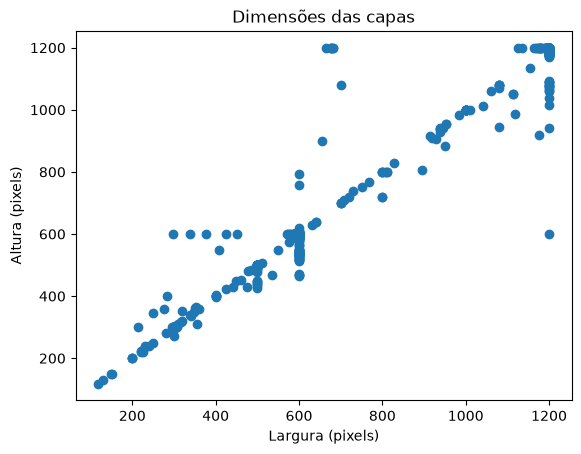

Dimensões mais frequentes:
[((600, 600), 1386), ((1200, 1200), 71), ((600, 595), 44), ((600, 596), 28), ((600, 597), 24), ((500, 500), 23), ((1000, 1000), 16), ((600, 598), 12), ((600, 594), 12), ((300, 300), 10)]
Capas repetidas: 246
Áudios sem capa correspondente: 197
Capas sem áudio correspondente: 0
Áudios analisados: 100
       Duração (s)  Energia RMS  Amplitude máxima  Zero crossing rate  \
count      100.000      100.000           100.000             100.000   
mean        29.928        0.165             0.909               0.119   
std          0.271        0.067             0.211               0.039   
min         29.127        0.032             0.143               0.031   
25%         29.979        0.109             0.775               0.091   
50%         30.060        0.160             0.941               0.113   
75%         30.060        0.203             1.049               0.142   
max         30.096        0.383             1.271               0.231   

       Centroi

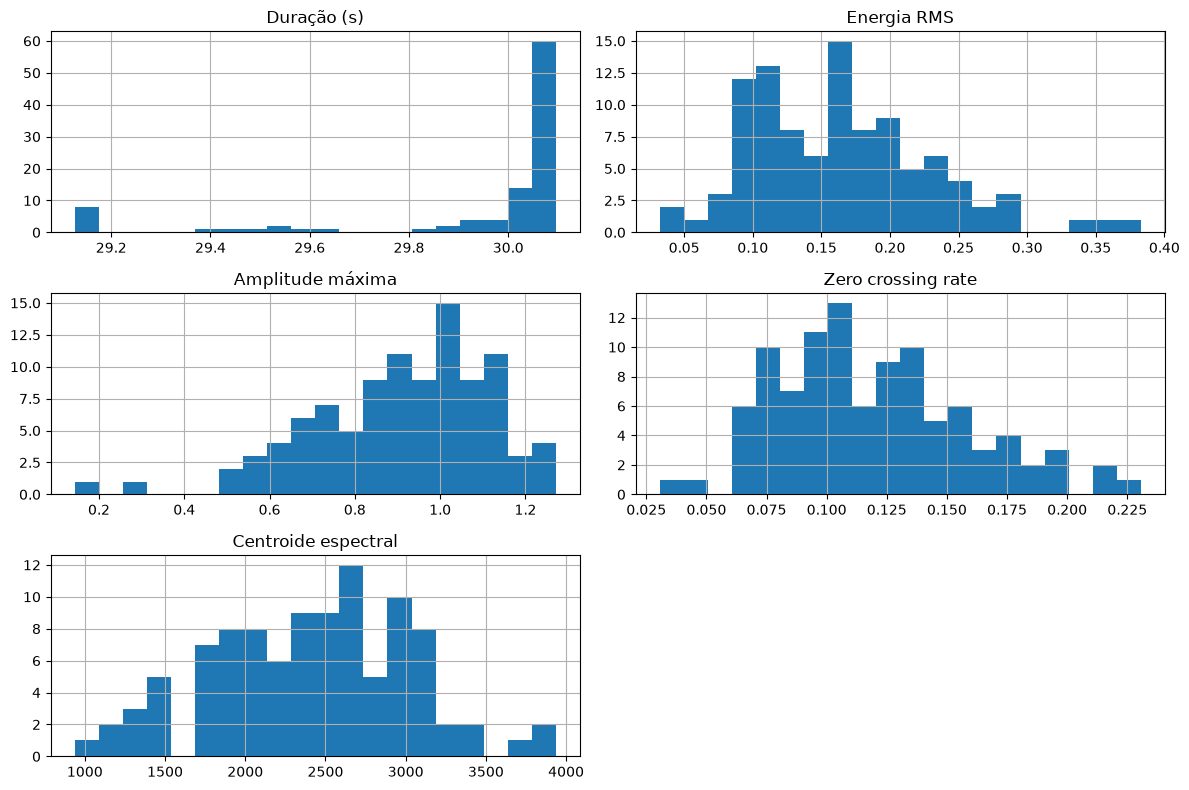

In [59]:
from pathlib import Path
from PIL import Image
from collections import Counter
import hashlib
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt

# Caminhos dos ficheiros
base = Path("dataset/dataset")
covers = list((base / "album_covers").rglob("*"))
covers = [p for p in covers if p.suffix.lower() in [".jpg", ".jpeg", ".png"]]
audios = [p for p in (base / "audio").rglob("*")
          if p.suffix.lower() in [".mp3", ".wav", ".flac", ".ogg", ".m4a"]]

print("Capas:", len(covers))
print("Áudios:", len(audios))

# 1. Dimensões das capas
dimensions = []
hashes = []

for p in covers:
    try:
        with Image.open(p) as img:
            dimensions.append((p.stem, *img.size))
            hashes.append(hashlib.md5(img.convert("RGB").tobytes()).hexdigest())
    except Exception:
        pass

covers_df = pd.DataFrame(dimensions, columns=["ID", "Width", "Height"])

plt.scatter(covers_df["Width"], covers_df["Height"])
plt.xlabel("Largura (pixels)")
plt.ylabel("Altura (pixels)")
plt.title("Dimensões das capas")
plt.show()

print("Dimensões mais frequentes:")
print(Counter(zip(covers_df["Width"], covers_df["Height"])).most_common(10))
print("Capas repetidas:", sum(n - 1 for n in Counter(hashes).values() if n > 1))

# 2. Capas em falta ou sem áudio correspondente
cover_ids = {p.stem for p in covers}
audio_ids = {p.stem for p in audios}

print("Áudios sem capa correspondente:", len(audio_ids - cover_ids))
print("Capas sem áudio correspondente:", len(cover_ids - audio_ids))

# 3. Estatísticas dos áudios
stats = []

for p in audios[:100]:
    try:
        y, sr = librosa.load(p, sr=22050, mono=True)

        if len(y) == 0:
            continue

        stats.append({
            "Duração (s)": len(y) / sr,
            "Energia RMS": np.sqrt(np.mean(y ** 2)),
            "Amplitude máxima": np.max(np.abs(y)),
            "Zero crossing rate": np.mean(
                librosa.feature.zero_crossing_rate(y=y)
            ),
            "Centroide espectral": np.mean(
                librosa.feature.spectral_centroid(y=y, sr=sr)
            )
        })

    except Exception as e:
        print(f"Erro em {p.name}: {e}")

stats_df = pd.DataFrame(stats)

print("Áudios analisados:", len(stats_df))
print(stats_df.describe().round(3))

stats_df.hist(bins=20, figsize=(12, 8))
plt.tight_layout()
plt.show()

4.5.1 - A análise das capas revelou que a dimensão mais frequente é 600 × 600 píxeis, existindo 246 capas repetidas. Foram também identificados 197 áudios sem capa correspondente e nenhuma capa sem áudio correspondente.Nos primeiros 100 áudios analisados, a duração média foi de aproximadamente 30 segundos. As restantes características, como a energia RMS e o centroide espectral, apresentaram alguma variabilidade.Estas situações podem afetar a extração de características multimédia e a avaliação do modelo. No entanto, é necessário investigar as duplicações e analisar todos os áudios para determinar o impacto real.